# 1. ODiSI: stochastic inversion by pseudo-well matching

This notebook reproduces the ODiSI result of the manuscript (Figures 7 and 8, ODiSI columns of
Tables 3, 4 and 6).

For every trace of the seismic line, ODiSI simulates 15,000 pseudo-wells from the prior, computes
their synthetic EEI, and keeps the 50 pseudo-wells whose EEI best matches the field EEI. The
mean, quartiles and facies frequencies of these 50 pseudo-wells are the result at the trace.
Each ODiSI run uses one EEI angle, so we run it at the four angles of the manuscript and then
take each property from the angle most sensitive to it at Well 2X:

| property | Vp | Vs | ρ | porosity | Vshale | facies |
|---|---|---|---|---|---|---|
| angle χ | −7.5° | −60° | 25° | 45° | 45° | 45° |

**Settings** (`CFG` in `ODiSI_libs/odisi_inversion.py`): prior of Tables 1 and 2 calibrated on
Well 2X; EEI band-passed 3–60 Hz; amplitude scale calibrated on the line; static shifts within
±4 ms; misfit computed per macrolayer; best 50 of 15,000 pseudo-wells per trace.

**Run time:** about 4 minutes on 16 CPU cores. ODiSI is deterministic, so the results are
identical to those of the manuscript.

**Outputs:** `Notebooks/outputs/ODiSI/chi_<χ>/` (one run per angle) and
`Notebooks/outputs/ODiSI/multichi_well2x/` (the result of the manuscript), as SEG-Y files on the
1 ms grid of the line, with figures in `figures/`.

In [1]:
%matplotlib inline
import json, shutil, time
import numpy as np
from IPython.display import Markdown, display
from nb_utils import *

environment()

FORCE = False          # True: rerun ODiSI even if its results exist
SEGY_TAG = "2x_9P_line_EEI_run_10_Nov_25"
WELL2X = dict(vp=-7.5, vs=-60.0, rho=25.0, poro=45.0, vshale=45.0)   # angle of each property
times = {}

Python 3.12.0, numpy 2.2.6


PyTorch 2.8.0+cu128, GPU: NVIDIA H100 80GB HBM3
CPU cores: 16
Package root: Stochastic_Inv_Code_Release/
Well 9P logs: not distributed (blind-well comparison skipped)


## 1.1 Input data

The field EEI at angle χ is computed from the AVO intercept A and gradient B of the line as
0.65 · (A cos χ + B sin χ) convolved with the wavelet, and band-passed 3–60 Hz (manuscript
Figure 6). The dashed lines are the macrolayer boundaries; the inversion window runs from the
top of the first macrolayer to the base of the last.

In [2]:
plot_field_eei(CHIS_4)

## 1.2 Prior

The pseudo-wells are drawn from the prior of the manuscript: a first-order Markov chain of facies
in each macrolayer (Table 1) and the rock-physics relations of Table 2, with AR(4) fluctuations
calibrated on Well 2X (`Data/rock_physics_2x.json`).

In [3]:
from odisi_inversion import CFG
names = ["shale", "silt", "sand", "calc. sand"]
for ml, L in enumerate(CFG["layers"], 1):
    T = np.asarray(L["T"], float)
    lam = np.atleast_1d(L["lam"])
    k = len(T)
    rows = {names[i]: dict({names[j]: T[i, j] for j in range(k)}, **{"λ (1/s)": float(lam[i]) if i < len(lam) else "–"})
            for i in range(k)}
    display(Markdown(f"**ML{ml}**: transition matrix (row: facies of a bed, column: facies of the next bed)"))
    table(rows, names[:k] + ["λ (1/s)"], fmt="{:.4g}", index_name="facies")

rp = json.loads((DATA_DIR / "rock_physics_2x.json").read_text())
print("AR(4) fluctuations fitted at Well 2X:")
for q, v in rp["residual_ar"].items():
    print(f"  {q:6s} std {v['std']:.4g}, AR coefficients " + ", ".join(f"{a:.3f}" for a in v["ar"]))

**ML1**: transition matrix (row: facies of a bed, column: facies of the next bed)

| facies | shale | silt | sand | λ (1/s) |
|---|---|---|---|---|
| shale | 0 | 0.6667 | 0.3333 | 63.9 |
| silt | 1 | 0 | 0 | 558.6 |
| sand | 0.6667 | 0.3333 | 0 | 1124 |

**ML2**: transition matrix (row: facies of a bed, column: facies of the next bed)

| facies | shale | silt | sand | calc. sand | λ (1/s) |
|---|---|---|---|---|---|
| shale | 0 | 0.5 | 0.5 | 0 | 198.8 |
| silt | 1 | 0 | 0 | 0 | 300.6 |
| sand | 0.5 | 0 | 0 | 0.5 | 312.7 |
| calc. sand | 0 | 0 | 1 | 0 | 845.8 |

**ML3**: transition matrix (row: facies of a bed, column: facies of the next bed)

| facies | shale | silt | sand | λ (1/s) |
|---|---|---|---|---|
| shale | 0 | 0.6667 | 0.3333 | 63.9 |
| silt | 1 | 0 | 0 | 558.6 |
| sand | 0.6667 | 0.3333 | 0 | 1124 |

AR(4) fluctuations fitted at Well 2X:
  vp     std 139.7, AR coefficients 0.443, -0.065, -0.076, 0.076
  por    std 0.01802, AR coefficients 0.057, 0.210, 0.104, -0.002


## 1.3 ODiSI at the four angles

Each run writes the mean, standard deviation and 25th and 75th percentiles of every property,
the most probable facies and the facies probabilities. The last line of each log gives the
coefficient of determination R² between the field EEI and the synthetic EEI of the best
pseudo-wells.

In [4]:
fit = {}
for chi in CHIS_4:
    d = ODISI_OUT / f"chi_{chi:g}"
    if FORCE or not (d / f"vp_mean_{SEGY_TAG}.segy").exists():
        times[f"ODiSI χ = {chi:g}°"] = run("odisi_inversion.py", f"--chi={chi}", "--outdir", d,
                                          log=d / "run.log", tail=3)
    else:
        print(f"χ = {chi:g}°: results exist, not rerun (FORCE = False)")
    log = (d / "run.log").read_text()
    fit[chi] = next((l.split(":", 1)[1].strip() for l in log.splitlines() if l.startswith("R^2")), "")
    run("make_paper_figures.py", "--input-dir", d, "--outdir", d / "figures", "--formats", "png", "pdf",
        "--dpi", "120", "--facies-classified", log=d / "figures" / "figures.log", tail=1)
    print()

$ python ODiSI_libs/odisi_inversion.py --chi=-60.0 --outdir Notebooks/outputs/ODiSI/chi_-60


  ...
  100%|██████████| 283/283 [00:29<00:00,  9.75it/s]
[44 s, full log: Notebooks/outputs/ODiSI/chi_-60/run.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/ODiSI/chi_-60 --outdir Notebooks/outputs/ODiSI/chi_-60/figures --formats png pdf --dpi 120 --facies-classified


  ...
    wrote Well_9p_elasto_petrophysics_10_Nov.png/pdf
[6 s, full log: Notebooks/outputs/ODiSI/chi_-60/figures/figures.log]

$ python ODiSI_libs/odisi_inversion.py --chi=-7.5 --outdir Notebooks/outputs/ODiSI/chi_-7.5


  ...
  100%|██████████| 283/283 [00:29<00:00,  9.67it/s]
[44 s, full log: Notebooks/outputs/ODiSI/chi_-7.5/run.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/ODiSI/chi_-7.5 --outdir Notebooks/outputs/ODiSI/chi_-7.5/figures --formats png pdf --dpi 120 --facies-classified


  ...
    wrote Well_9p_elasto_petrophysics_10_Nov.png/pdf
[6 s, full log: Notebooks/outputs/ODiSI/chi_-7.5/figures/figures.log]

$ python ODiSI_libs/odisi_inversion.py --chi=25.0 --outdir Notebooks/outputs/ODiSI/chi_25


  ...
  100%|██████████| 283/283 [00:29<00:00,  9.60it/s]
[44 s, full log: Notebooks/outputs/ODiSI/chi_25/run.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/ODiSI/chi_25 --outdir Notebooks/outputs/ODiSI/chi_25/figures --formats png pdf --dpi 120 --facies-classified


  ...
    wrote Well_9p_elasto_petrophysics_10_Nov.png/pdf
[5 s, full log: Notebooks/outputs/ODiSI/chi_25/figures/figures.log]

$ python ODiSI_libs/odisi_inversion.py --chi=45.0 --outdir Notebooks/outputs/ODiSI/chi_45


  ...
  100%|██████████| 283/283 [00:30<00:00,  9.41it/s]
[45 s, full log: Notebooks/outputs/ODiSI/chi_45/run.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/ODiSI/chi_45 --outdir Notebooks/outputs/ODiSI/chi_45/figures --formats png pdf --dpi 120 --facies-classified


  ...
    wrote Well_9p_elasto_petrophysics_10_Nov.png/pdf
[5 s, full log: Notebooks/outputs/ODiSI/chi_45/figures/figures.log]



Mean of the best-matching pseudo-wells at each angle:

**χ = -60°** — fit to the field EEI: best pseudo-well 0.524, mean of best 50 0.644

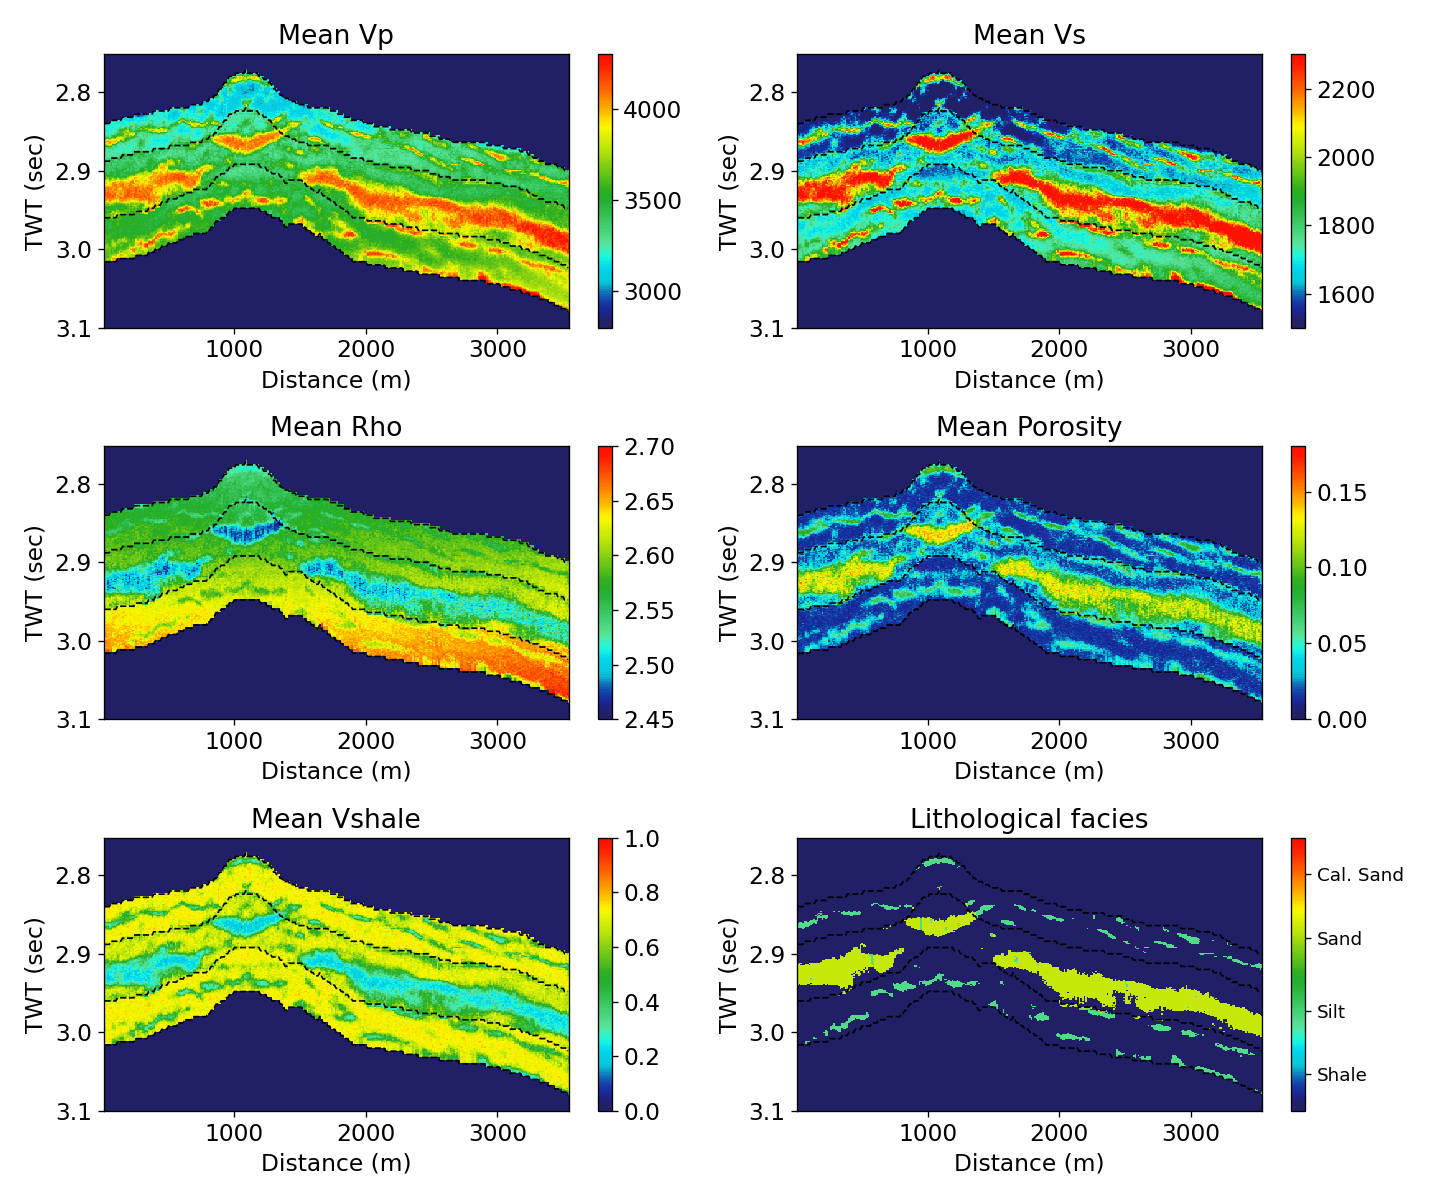

**χ = -7.5°** — fit to the field EEI: best pseudo-well 0.533, mean of best 50 0.599

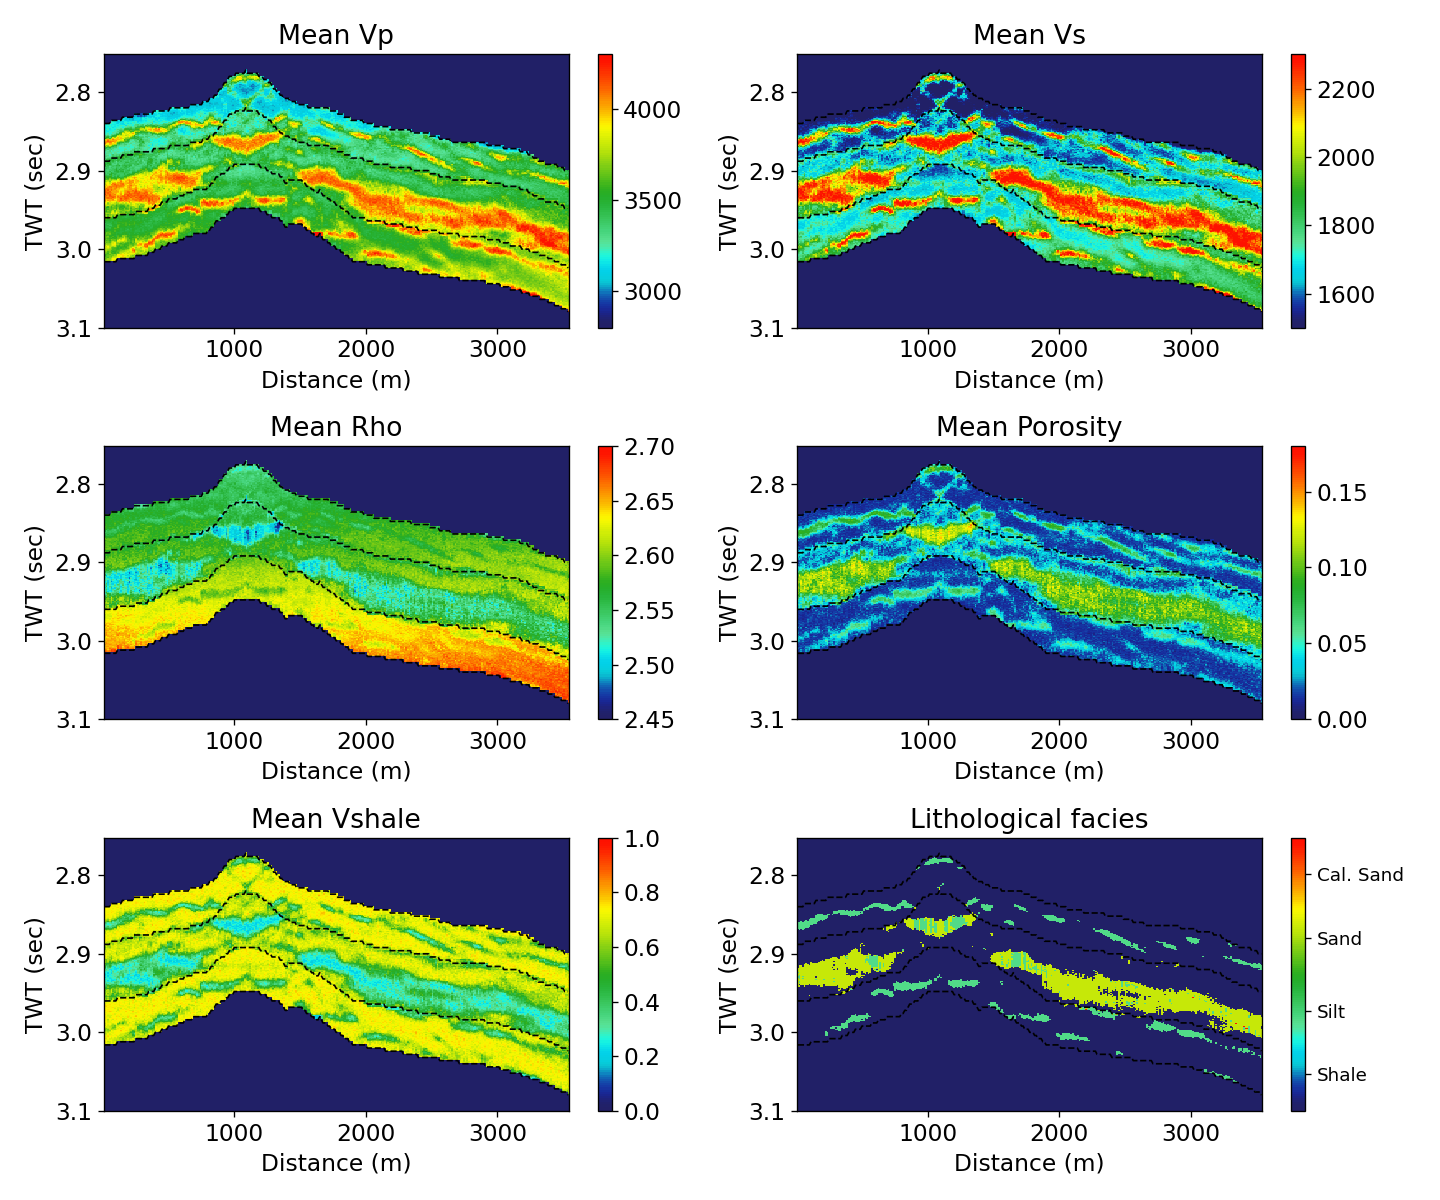

**χ = 25°** — fit to the field EEI: best pseudo-well 0.544, mean of best 50 0.698

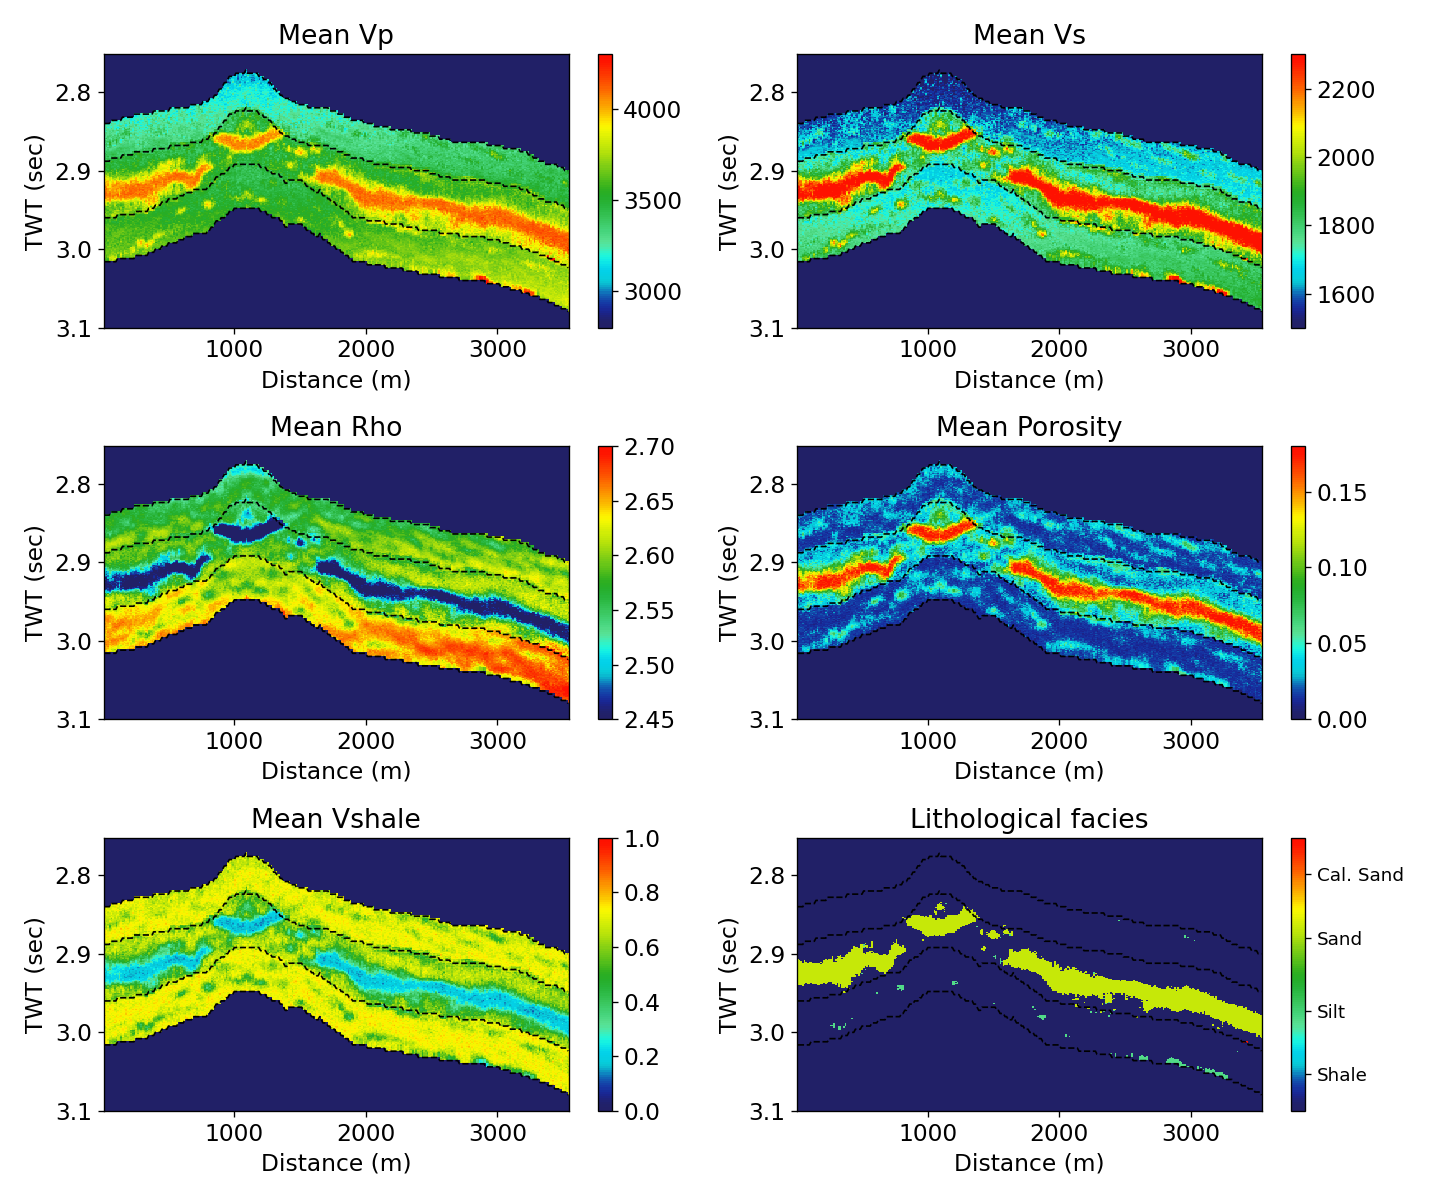

**χ = 45°** — fit to the field EEI: best pseudo-well 0.503, mean of best 50 0.666

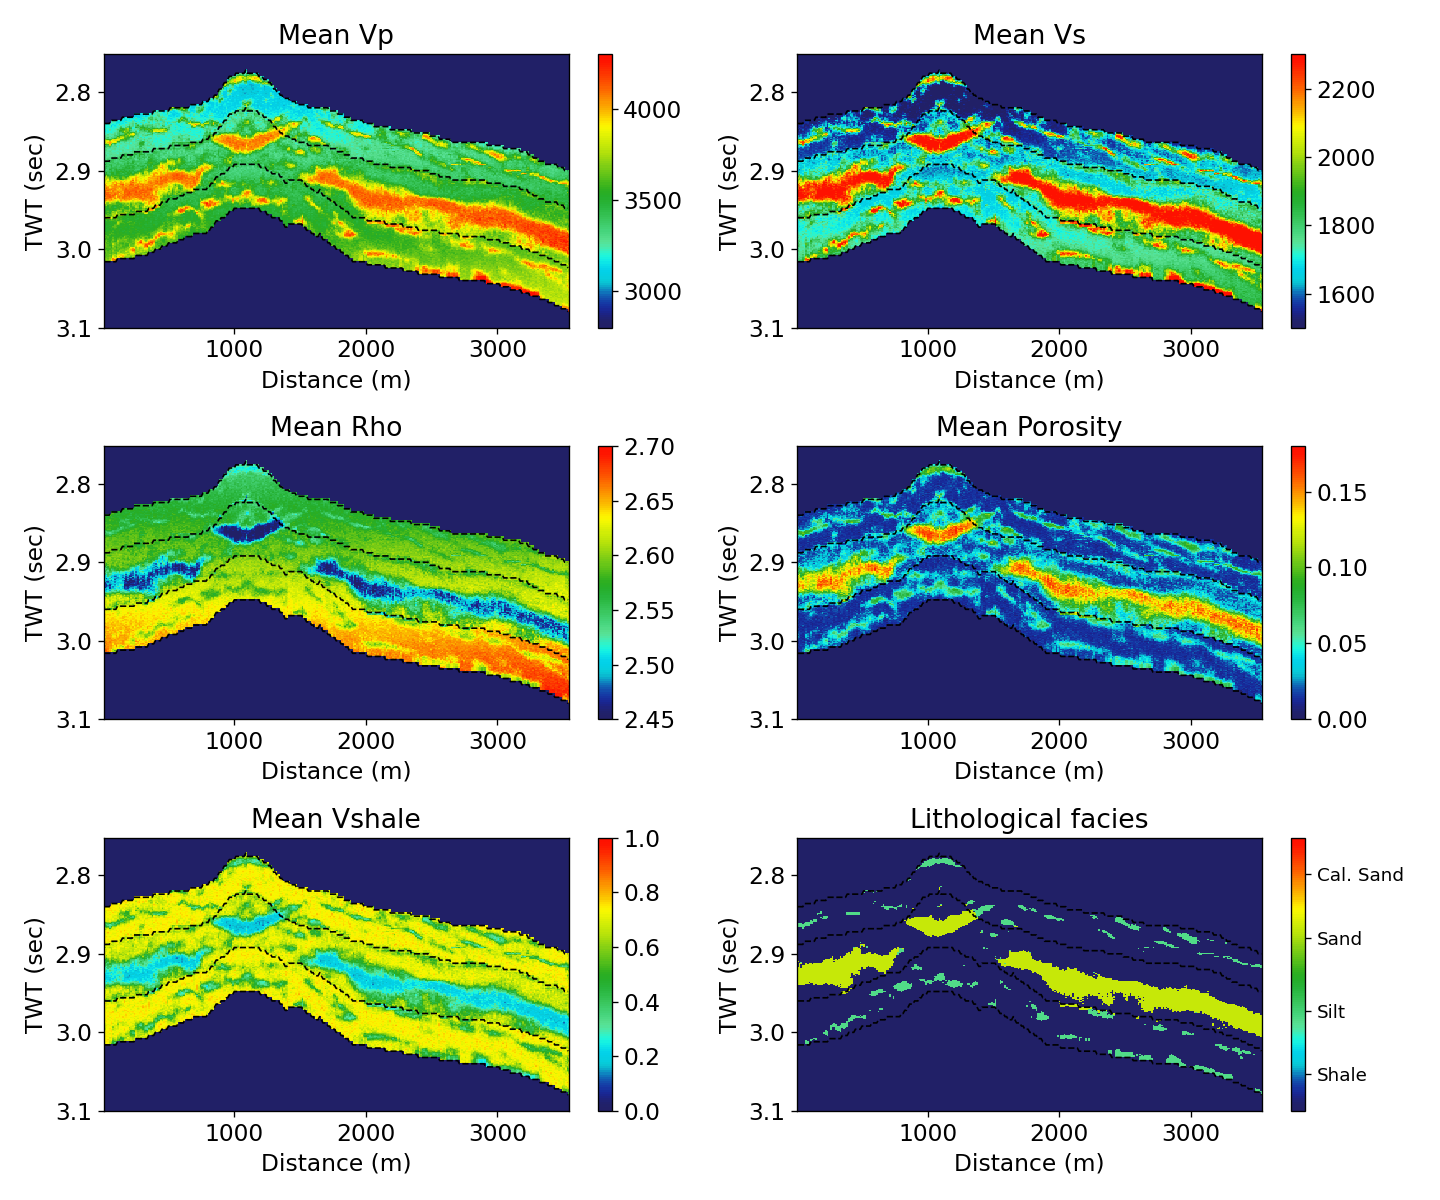

In [5]:
for chi in CHIS_4:
    display(Markdown(f"**χ = {chi:g}°** — fit to the field EEI: {fit[chi]}"))
    show(first(ODISI_OUT / f"chi_{chi:g}" / "figures", "Stochastic_inversion_*.png"))

Quality control at χ = 45°: the 100 best pseudo-wells at the QC trace and their synthetic EEI
compared with the field EEI.

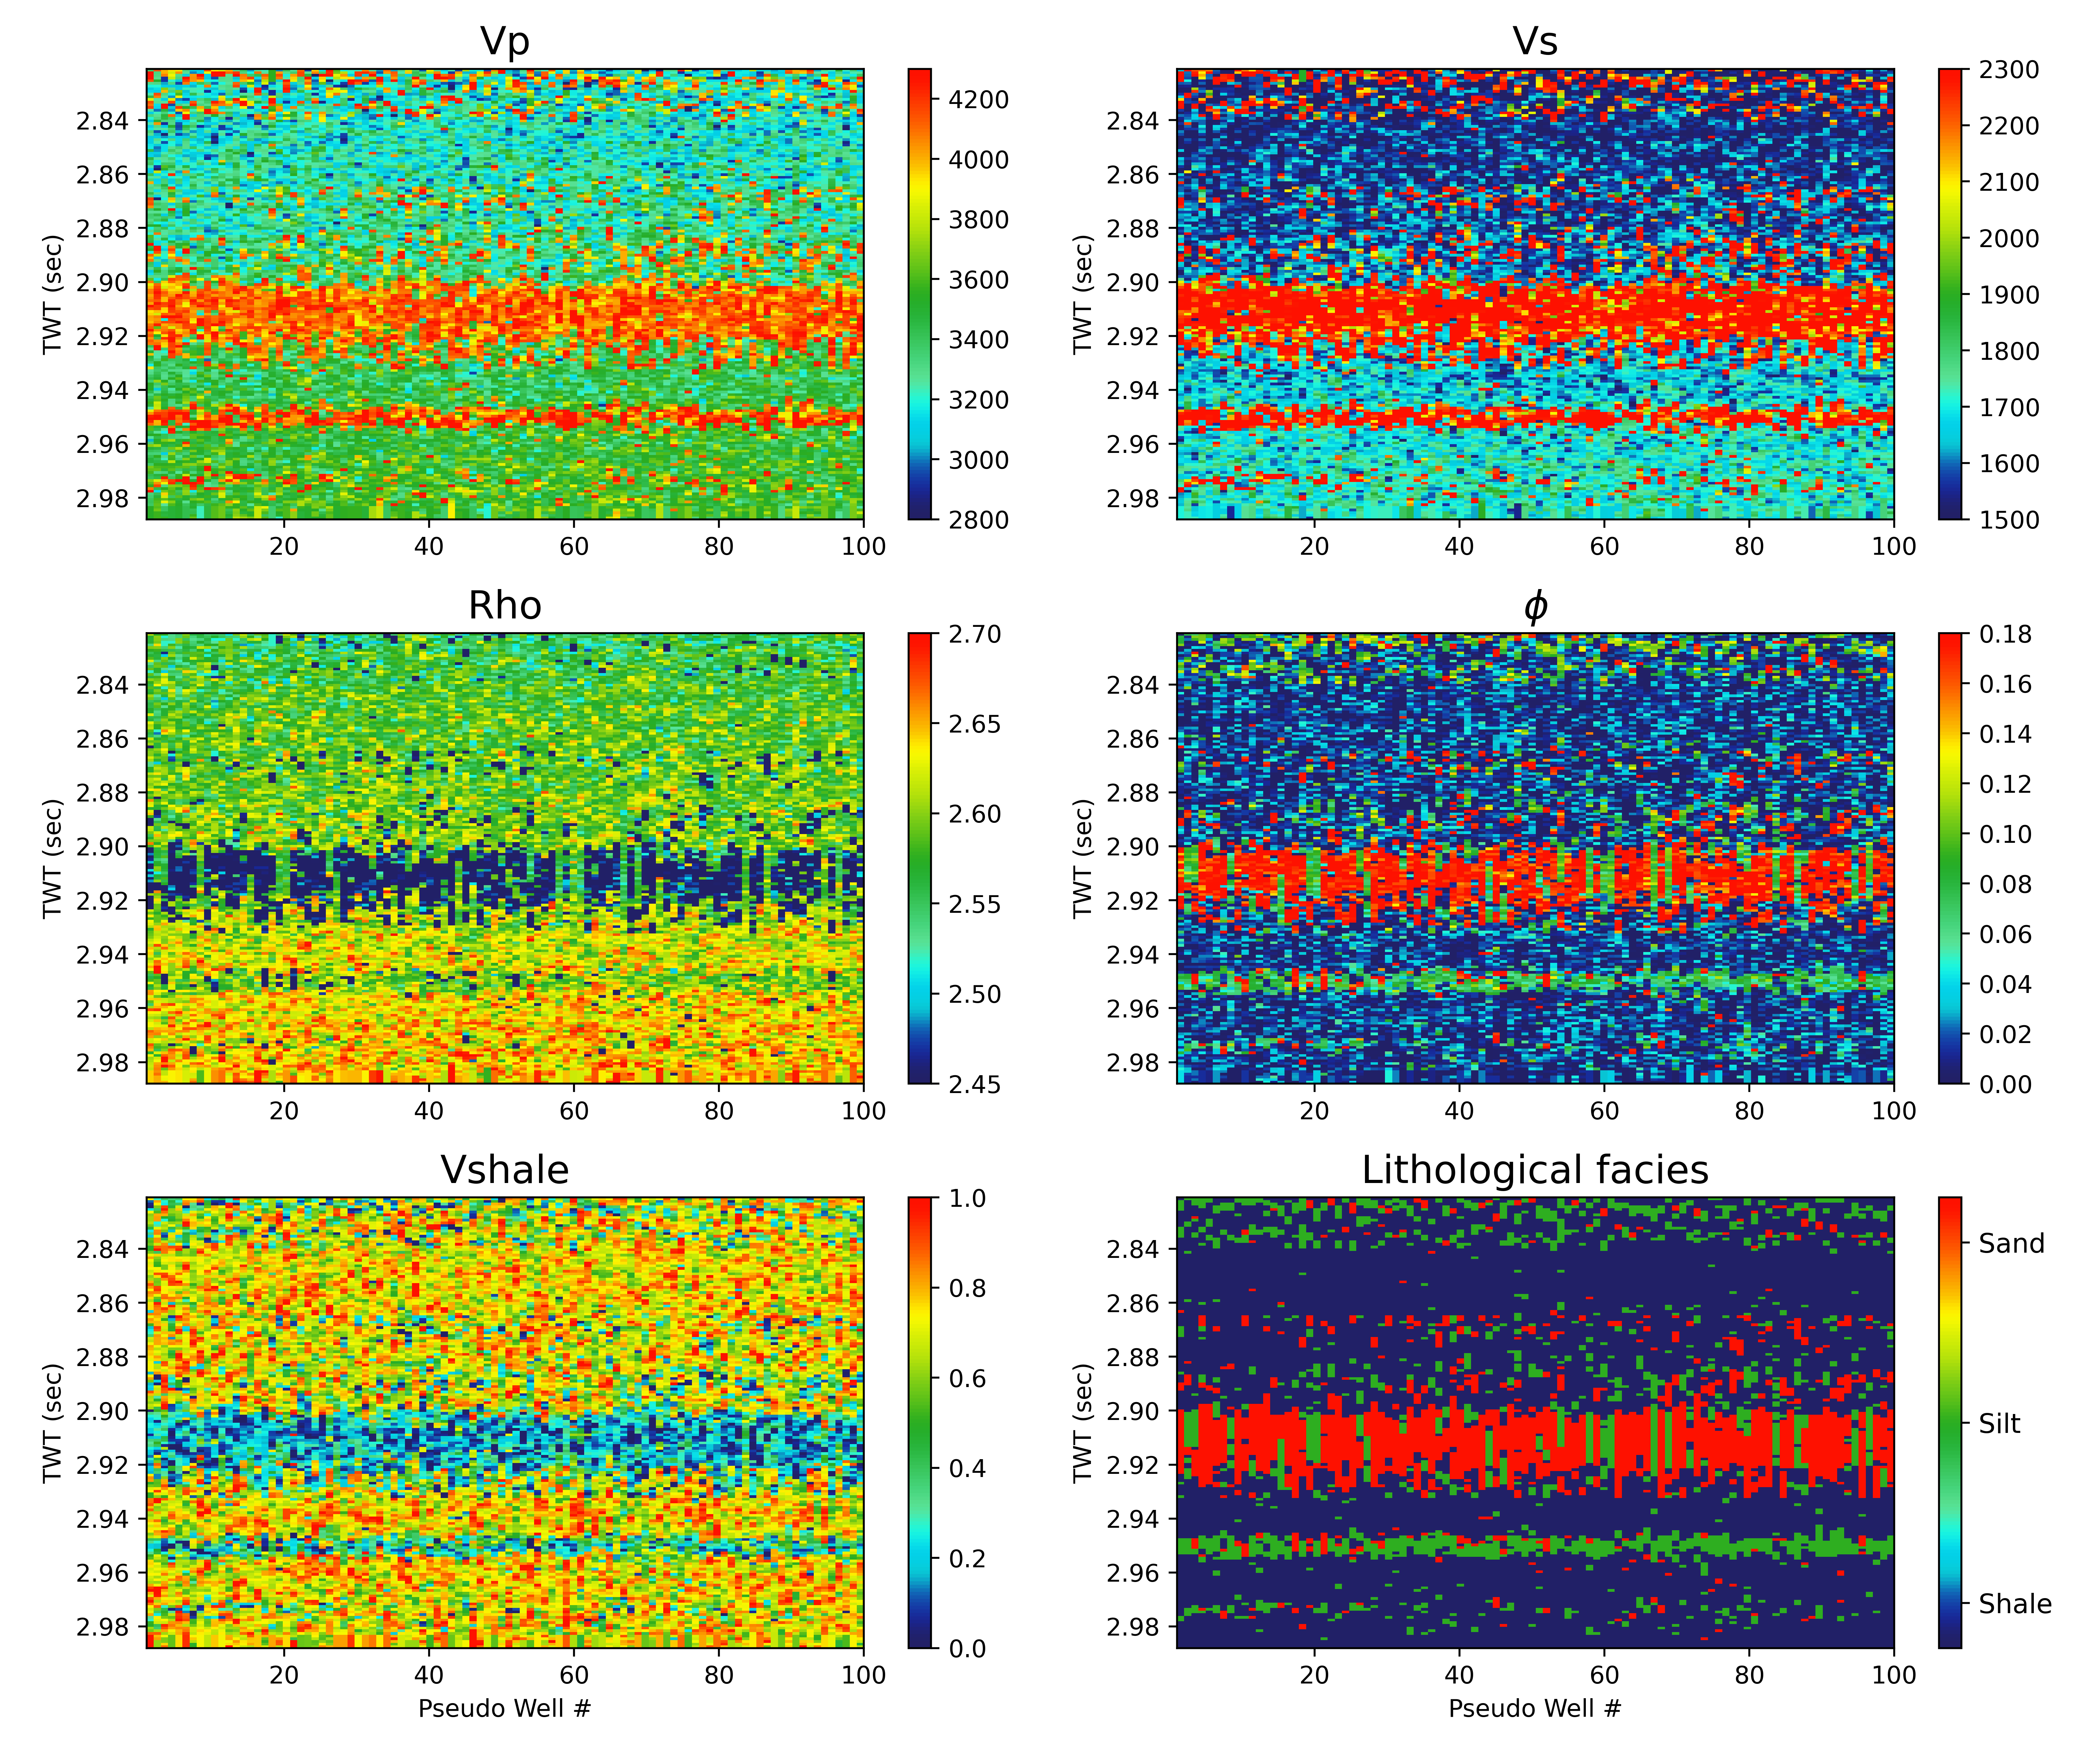

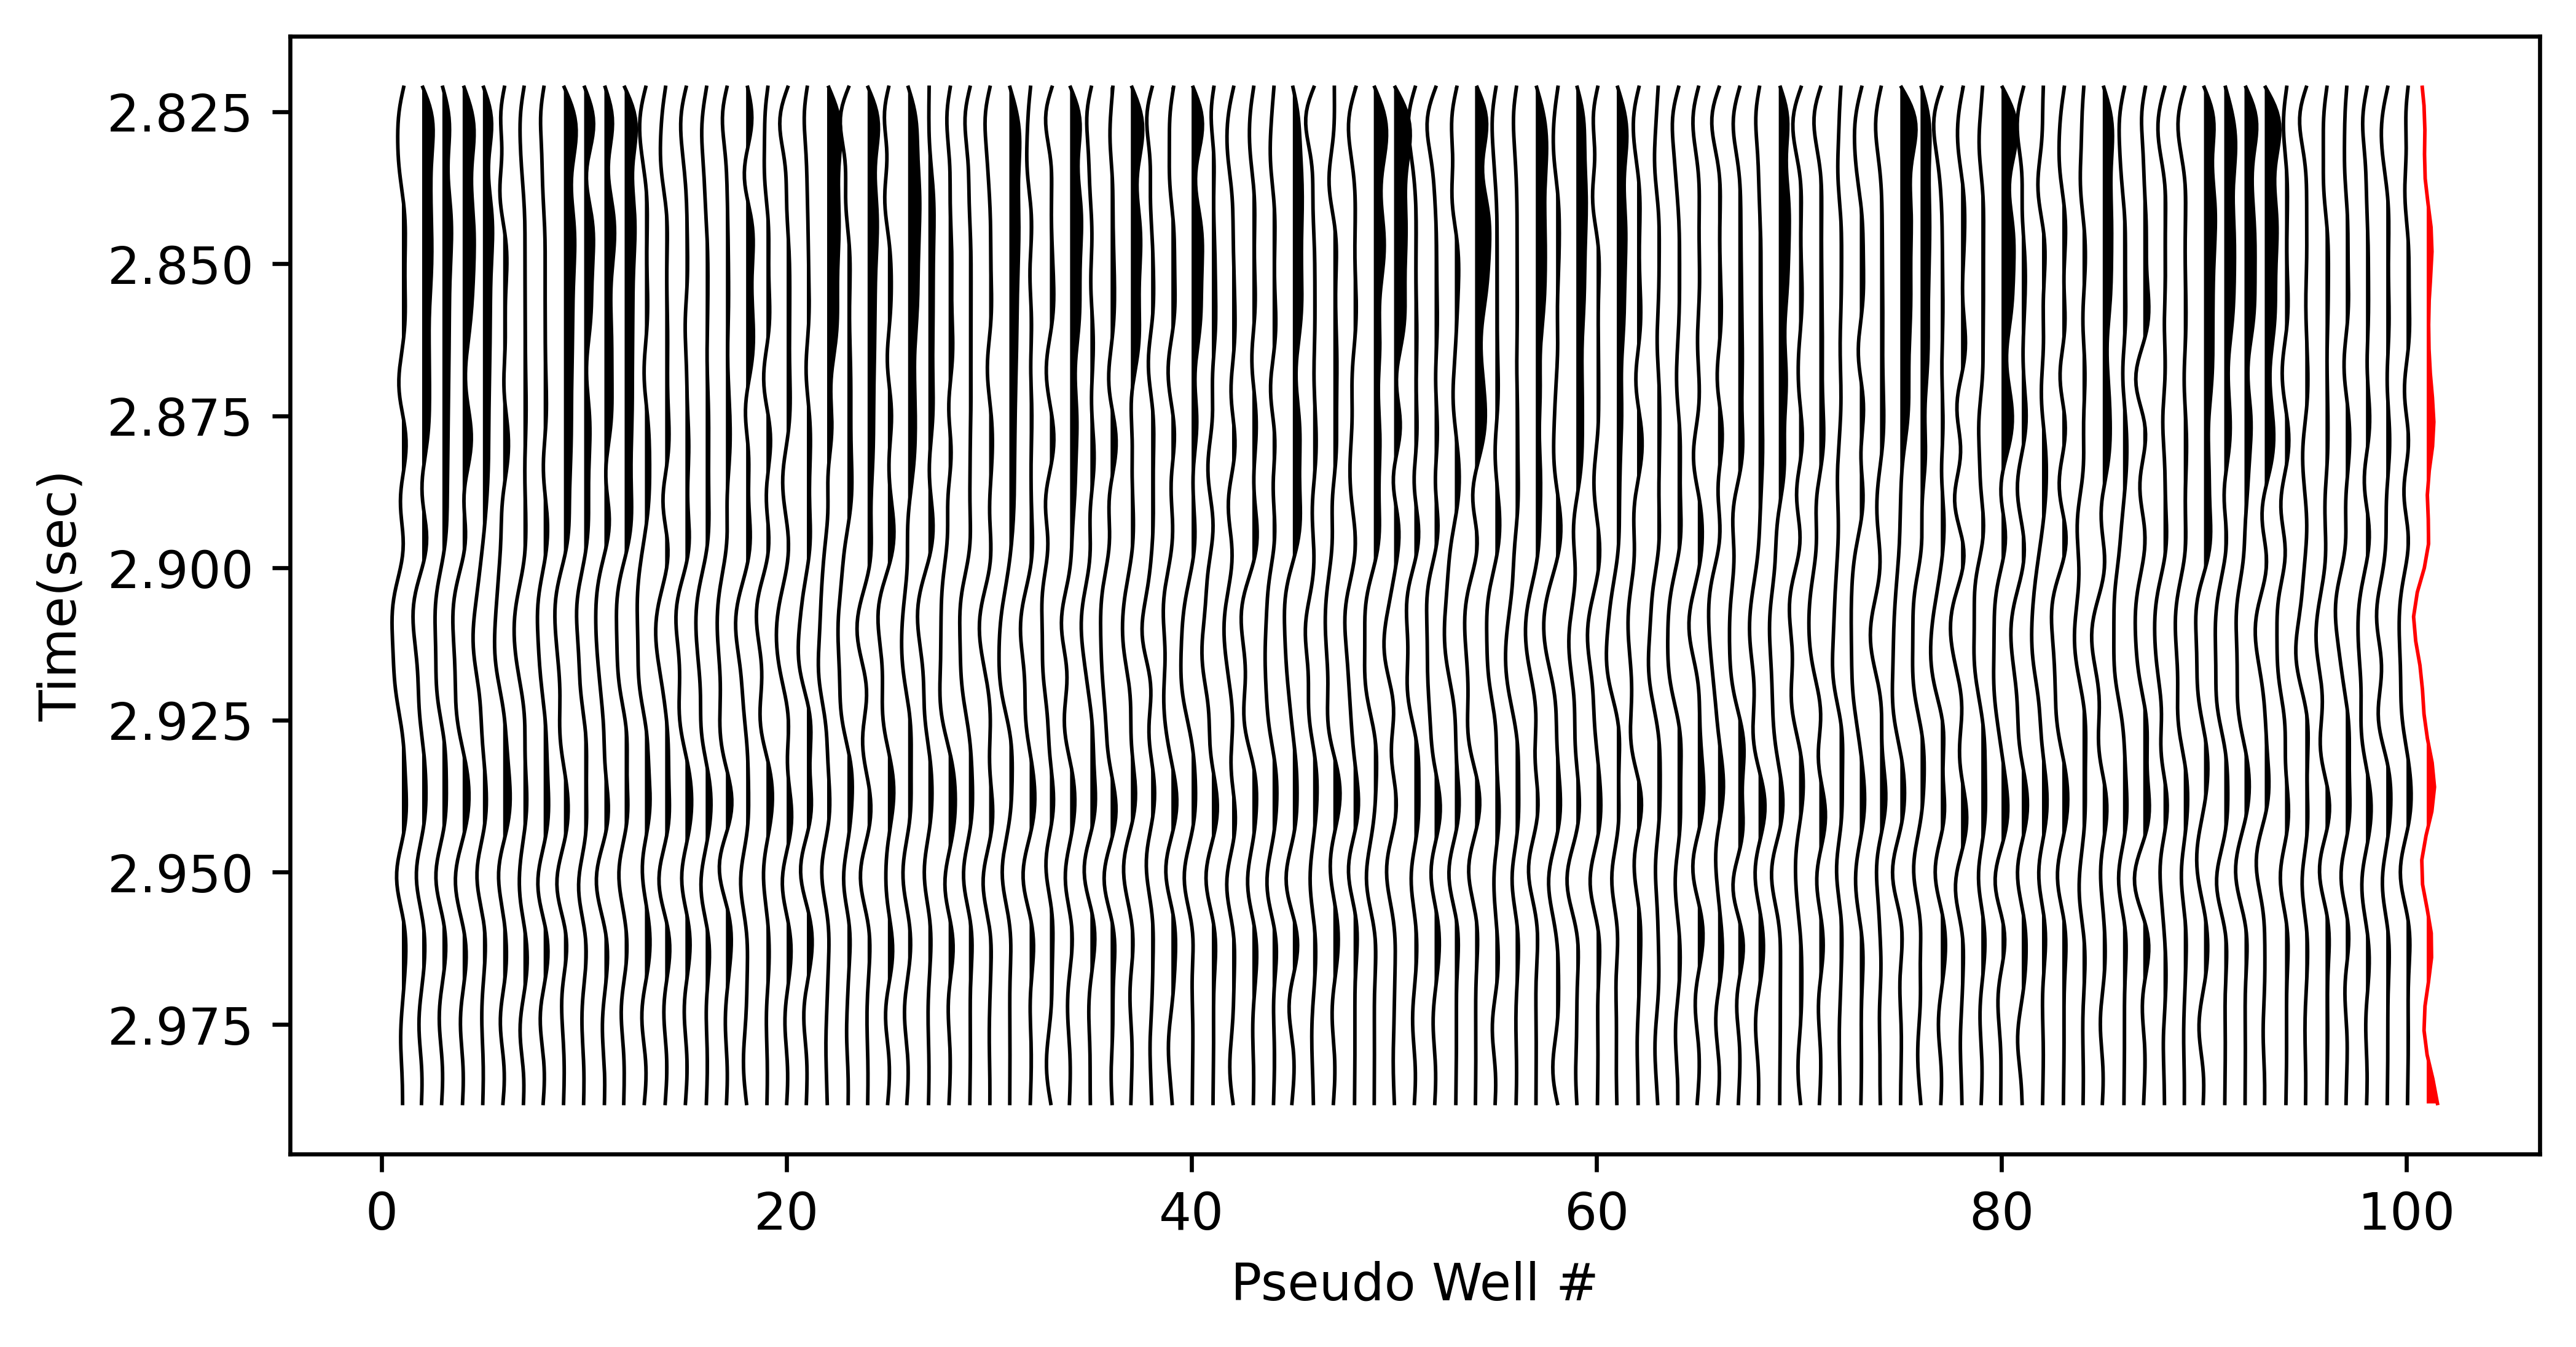

In [6]:
d = ODISI_OUT / "chi_45"
show(first(d, "Best_100_wells_*.png"), first(d, "Best_100_psedowells_seismic_*.png"), width=850)

## 1.4 ODiSI result of the manuscript (multi-angle)

Each property is taken from its angle (table at the top). The angles were fixed from the
sensitivity analysis at Well 2X (manuscript Figure 4), before any comparison with Well 9P.

In [7]:
d = ODISI_OUT / "multichi_well2x"
d.mkdir(parents=True, exist_ok=True)
for p, chi in WELL2X.items():
    for st in ("mean", "std", "q25", "q75"):
        name = f"{p}_{st}_{SEGY_TAG}.segy"
        shutil.copyfile(ODISI_OUT / f"chi_{chi:g}" / name, d / name)
for name in ("facies", "prob_shale", "prob_silt", "prob_sand", "prob_calcareous_sand"):
    shutil.copyfile(ODISI_OUT / f"chi_{WELL2X['vshale']:g}" / f"{name}_{SEGY_TAG}.segy",
                    d / f"{name}_{SEGY_TAG}.segy")
(d / "SOURCES.txt").write_text("".join(f"{p}: chi={c:g}\n" for p, c in WELL2X.items()) +
                               "facies and facies probabilities: chi=45\n")
run("make_paper_figures.py", "--input-dir", d, "--outdir", d / "figures", "--formats", "png", "pdf",
    "--dpi", "120", "--facies-classified", log=d / "figures" / "figures.log", tail=3)

$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/ODiSI/multichi_well2x --outdir Notebooks/outputs/ODiSI/multichi_well2x/figures --formats png pdf --dpi 120 --facies-classified


  ...
    wrote Cal_seismic_data_10_Nov.png/pdf
    Data/well9p_data.mat not found — Figure 3 shows the inversion only, no well logs or correlations
    wrote Well_9p_elasto_petrophysics_10_Nov.png/pdf
[5 s, full log: Notebooks/outputs/ODiSI/multichi_well2x/figures/figures.log]


5.102707386016846

**Manuscript Figure 7**: ODiSI sections of Vp, Vs, ρ, porosity, Vshale and facies.

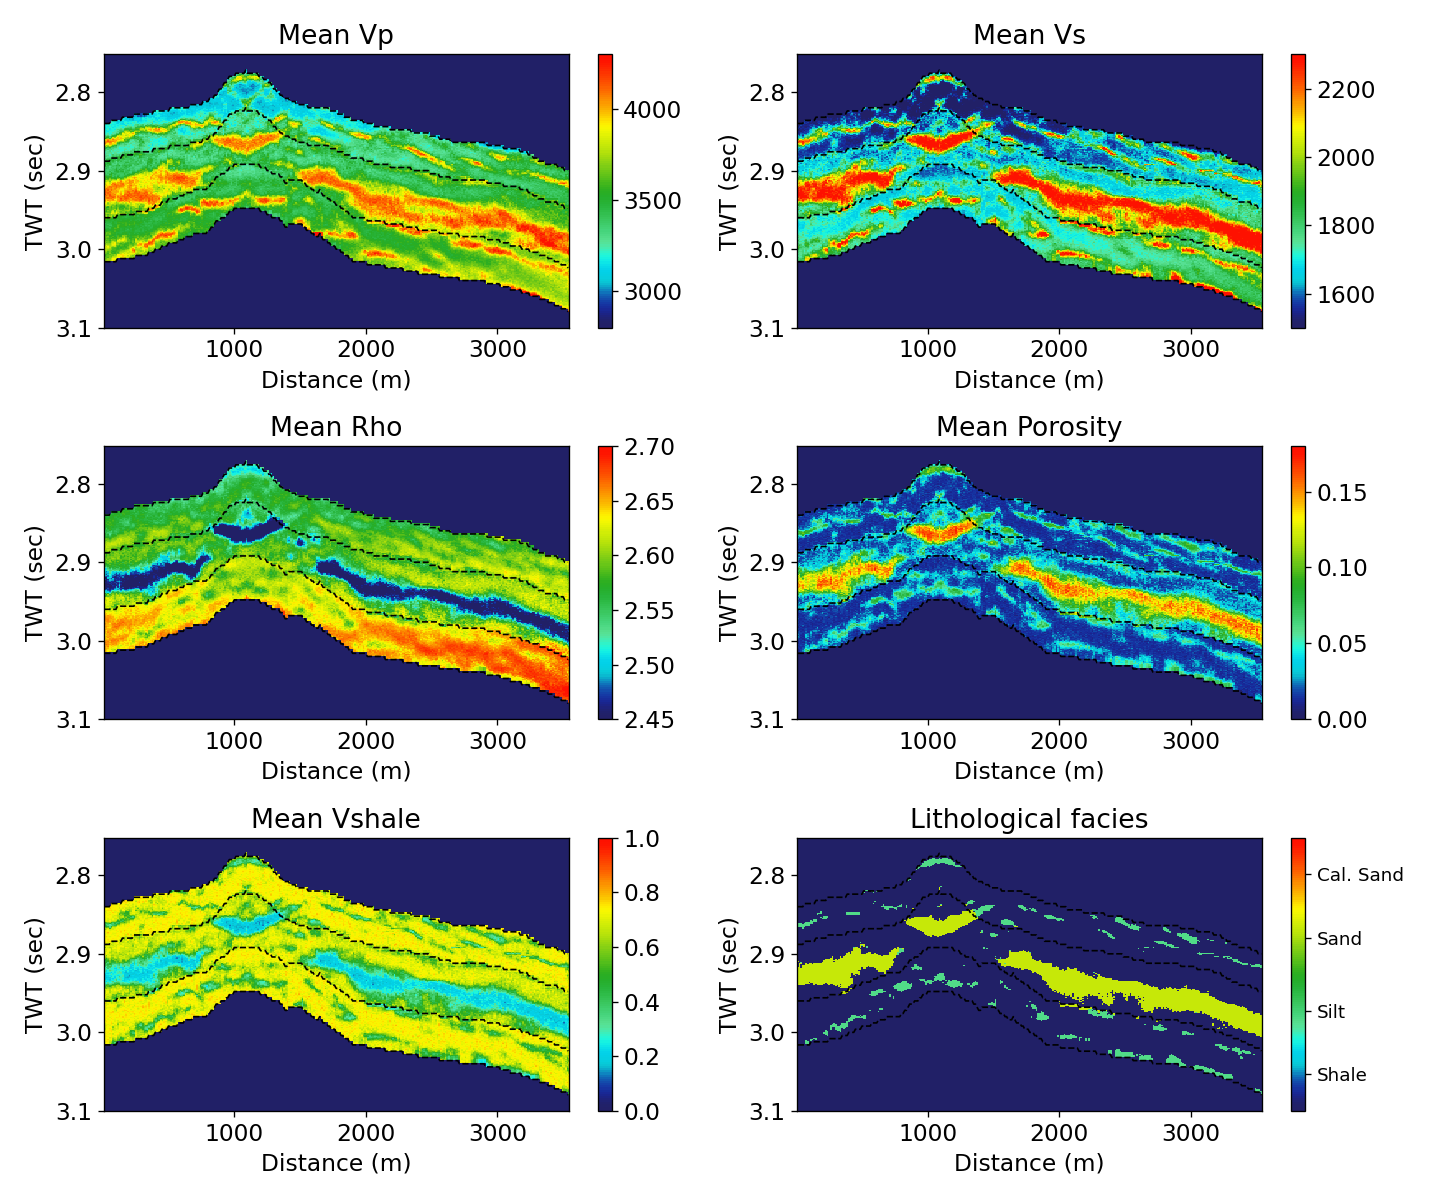

In [8]:
show(first(ODISI_OUT / "multichi_well2x" / "figures", "Stochastic_inversion_*.png"))

**Manuscript Figure 8**: the result along the path of Well 9P (mean, 25th and 75th percentiles).
The Well 9P logs are proprietary and not distributed, so without them the panel shows the
inversion only.

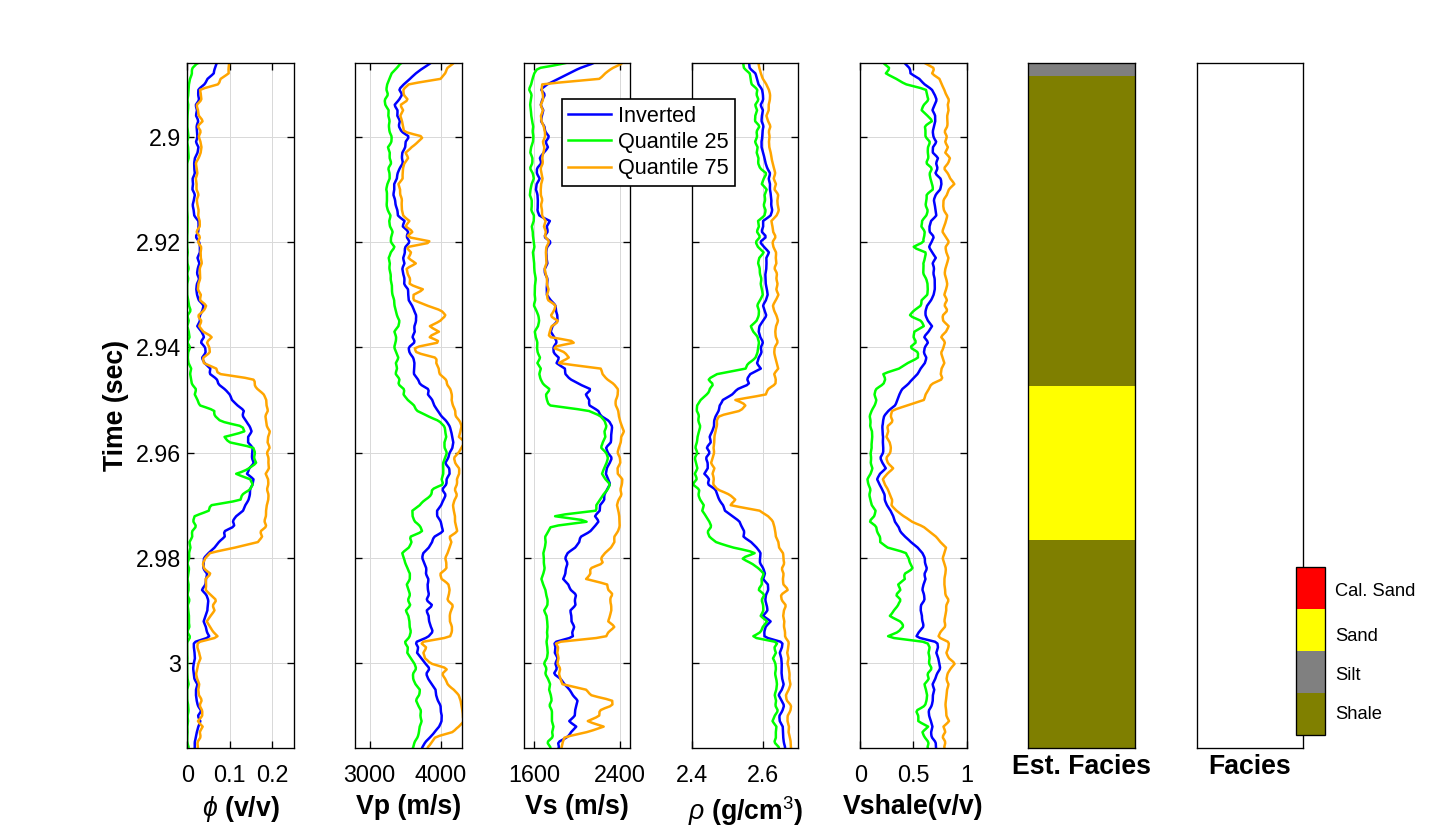

In [9]:
show(first(ODISI_OUT / "multichi_well2x" / "figures", "Well_9p_elasto_petrophysics_*.png"), width=900)

## 1.5 Blind-well comparison and computing time

When `Data/well9p_data.mat` is present, the correlation coefficients at Well 9P
(2.886–3.016 s) are read from the figure script. The values of the manuscript (Table 3) are:

| Vp | Vs | ρ | Vshale | φ | mean |
|---|---|---|---|---|---|
| 0.681 | 0.763 | 0.684 | 0.651 | 0.630 | 0.682 |

In [10]:
r = read_well_correlation(first(ODISI_OUT / "multichi_well2x" / "figures", "well_correlation_*.txt"))
if r:
    table({"ODiSI, this run": r}, list(PROPS))
else:
    print("Well 9P logs not available: blind-well correlations not computed.")

if times:
    total = sum(times.values())
    times["total, 283 traces"] = total
    table({k: {"time (s)": v} for k, v in times.items()}, ["time (s)"], fmt="{:.0f}", index_name="step")
    print(f"time per trace: {total / 283:.2f} s (manuscript Table 6: 146 s in total, 0.52 s per trace)")

Well 9P logs not available: blind-well correlations not computed.


| step | time (s) |
|---|---|
| ODiSI χ = -60° | 44 |
| ODiSI χ = -7.5° | 44 |
| ODiSI χ = 25° | 44 |
| ODiSI χ = 45° | 45 |
| total, 283 traces | 176 |

time per trace: 0.62 s (manuscript Table 6: 146 s in total, 0.52 s per trace)
